In [19]:
import pandas as pd
import torch
import numpy as np
import random
import os

import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [20]:
train_df = pd.read_csv("../data/burgers_train.csv")
test_df = pd.read_csv("../data/burgers_test.csv")

In [21]:
param_cols = ['A_initial', 'frequency_k', 'viscosity_nu']
x_cols = [col for col in train_df.columns if col.startswith('x_grid_')]
t_cols = [col for col in train_df.columns if col.startswith('t_grid_')]
u_cols = [col for col in train_df.columns if col.startswith('u_')]

# Recover unique spatial and temporal coordinates from the first sample.
# In this dataset, x_grid values repeat every time step and t_grid values repeat for each x.
x_unique = train_df[x_cols].iloc[0].values[:32].astype(np.float32)
t_unique = train_df[t_cols].iloc[0].values[::32].astype(np.float32)

print('params dim:', len(param_cols))
print('unique x dim:', len(x_unique))
print('unique t dim:', len(t_unique))
print('output dim:', len(u_cols))

params dim: 3
unique x dim: 32
unique t dim: 500
output dim: 16000


In [22]:
def prepare_mlp_tensors(df, scaler=None):
    params = df[param_cols].values.astype(np.float32)
    x_grid = np.repeat(x_unique.reshape(1, -1), len(df), axis=0)
    t_grid = np.repeat(t_unique.reshape(1, -1), len(df), axis=0)

    X_raw = np.concatenate([params, x_grid, t_grid], axis=1)
    Y = df[u_cols].values.astype(np.float32)

    if scaler is None:
        scaler = StandardScaler().fit(X_raw)
    X_scaled = scaler.transform(X_raw)

    X = torch.tensor(X_scaled, dtype=torch.float32)
    Y = torch.tensor(Y, dtype=torch.float32)
    return X, Y, scaler

X_train, Y_train, scaler_X = prepare_mlp_tensors(train_df)
X_test, Y_test, _ = prepare_mlp_tensors(test_df, scaler_X)

print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

X_train shape: torch.Size([400, 535])
Y_train shape: torch.Size([400, 16000])


In [23]:
class BurgersMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(512, 512, 256), output_dim=None):
        super().__init__()
        if output_dim is None:
            raise ValueError('output_dim must be specified')

        layers = []
        dims = [input_dim] + list(hidden_dims)
        for in_dim, out_dim in zip(dims[:-1], dims[1:]):
            layers.append(nn.Linear(in_dim, out_dim))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(dims[-1], output_dim))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class RelativeL2Loss(object):
    def __call__(self, y_pred, y_true):
        num_examples = y_pred.size(0)
        diff_norms = torch.norm(
            y_pred.reshape(num_examples, -1) - y_true.reshape(num_examples, -1), 2, 1
        )
        true_norms = torch.norm(y_true.reshape(num_examples, -1), 2, 1)
        return torch.mean(diff_norms / (true_norms + 1e-8))

In [24]:
def sample_hyperparameters(space):
    return {k: random.choice(v) for k, v in space.items()}

def train_mlp(config, epochs=15):
    train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=config['batch_size'], shuffle=True)
    test_loader = DataLoader(TensorDataset(X_test, Y_test), batch_size=config['batch_size'], shuffle=False)

    model = BurgersMLP(input_dim=X_train.shape[1], hidden_dims=config['hidden_dims'], output_dim=Y_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    criterion = RelativeL2Loss()

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        for X_batch, Y_batch in train_loader:
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, Y_batch)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * X_batch.size(0)

        avg_train_loss = running_train_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for X_batch, Y_batch in test_loader:
                pred = model(X_batch)
                running_val_loss += criterion(pred, Y_batch).item() * X_batch.size(0)

        avg_val_loss = running_val_loss / len(test_loader.dataset)
        val_losses.append(avg_val_loss)

    return model, train_losses, val_losses, avg_val_loss

In [25]:
# Random search for the best MLP configuration

PARAM_SPACE_MLP = {
    'hidden_dims': [
        (512, 512, 256),
        (512, 256, 256),
        (256, 256, 256),
        (512, 512, 512),
    ],
    'lr': [5e-4, 1e-3, 2e-3],
    'batch_size': [16, 32, 64],
}

NUM_SEARCH_ITERATIONS = 8
best_val = float('inf')
best_config = None
best_search_results = []

print('Starting random search for MLP Burgers...')
for trial in range(NUM_SEARCH_ITERATIONS):
    config = sample_hyperparameters(PARAM_SPACE_MLP)
    _, train_hist, val_hist, val_loss = train_mlp(config, epochs=10)
    best_search_results.append((trial + 1, config, val_loss))
    print(f'Trial {trial + 1}/{NUM_SEARCH_ITERATIONS}: config={config}, val_loss={val_loss:.6f}')
    if val_loss < best_val:
        best_val = val_loss
        best_config = config

print('\nBest random search config:', best_config)
print('Best validation loss:', best_val)

Starting random search for MLP Burgers...
Trial 1/8: config={'hidden_dims': (512, 512, 256), 'lr': 0.001, 'batch_size': 32}, val_loss=0.028780
Trial 2/8: config={'hidden_dims': (512, 256, 256), 'lr': 0.001, 'batch_size': 16}, val_loss=0.027801
Trial 3/8: config={'hidden_dims': (256, 256, 256), 'lr': 0.001, 'batch_size': 32}, val_loss=0.020106
Trial 4/8: config={'hidden_dims': (512, 512, 512), 'lr': 0.001, 'batch_size': 16}, val_loss=0.014552
Trial 5/8: config={'hidden_dims': (512, 512, 256), 'lr': 0.0005, 'batch_size': 16}, val_loss=0.018717
Trial 6/8: config={'hidden_dims': (512, 512, 256), 'lr': 0.002, 'batch_size': 64}, val_loss=0.043856
Trial 7/8: config={'hidden_dims': (512, 512, 256), 'lr': 0.0005, 'batch_size': 64}, val_loss=0.071394
Trial 8/8: config={'hidden_dims': (512, 256, 256), 'lr': 0.002, 'batch_size': 16}, val_loss=0.020339

Best random search config: {'hidden_dims': (512, 512, 512), 'lr': 0.001, 'batch_size': 16}
Best validation loss: 0.014552471712231636


In [26]:
# Final training with the best configuration
final_epochs = 40
final_model, final_train_losses, final_val_losses, final_val = train_mlp(best_config, epochs=final_epochs)
print(f'Final retrained model validation loss: {final_val:.6f}')

model_save_path = 'best_mlp_burgers.pth'
torch.save(final_model.state_dict(), model_save_path)
print(f'Saved model to {model_save_path}')

Final retrained model validation loss: 0.010970
Saved model to best_mlp_burgers.pth


In [27]:
output_dir = '../Plots/MLP_burgers_plots'
os.makedirs(output_dir, exist_ok=True)

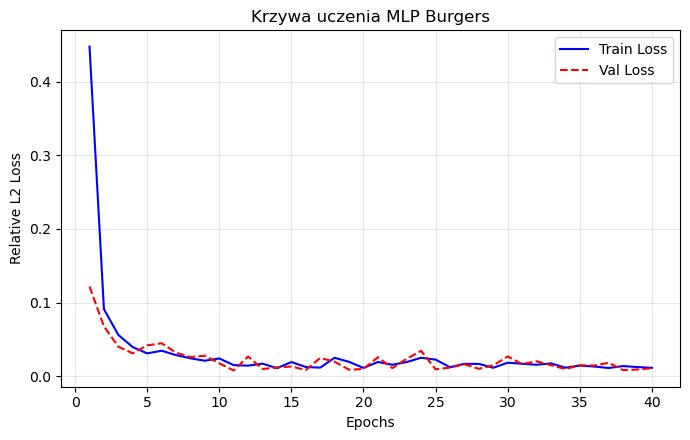

In [28]:
# Plot training history
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, final_epochs + 1), final_train_losses, label='Train Loss', color='blue')
plt.plot(range(1, final_epochs + 1), final_val_losses, label='Val Loss', color='red', linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Relative L2 Loss')
plt.title('Krzywa uczenia MLP Burgers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'loss_history_MLP_Burgers.png'), dpi=300, bbox_inches='tight')
plt.show()

In [29]:
# Evaluate the final model on the full test set for DeepONet-style plotting
final_model.eval()
all_preds = []
all_targets = []
with torch.no_grad():
    test_loader_full = DataLoader(TensorDataset(X_test, Y_test), batch_size=32, shuffle=False)
    for X_batch, Y_batch in test_loader_full:
        preds = final_model(X_batch)
        all_preds.append(preds.cpu().numpy())
        all_targets.append(Y_batch.cpu().numpy())

all_preds = np.concatenate(all_preds, axis=0)
all_targets = np.concatenate(all_targets, axis=0)
all_preds_mesh = all_preds.reshape(-1, len(t_unique), len(x_unique))
all_targets_mesh = all_targets.reshape(-1, len(t_unique), len(x_unique))
abs_error_mesh = np.abs(all_targets_mesh - all_preds_mesh)

x_axis = x_unique
time_axis = t_unique

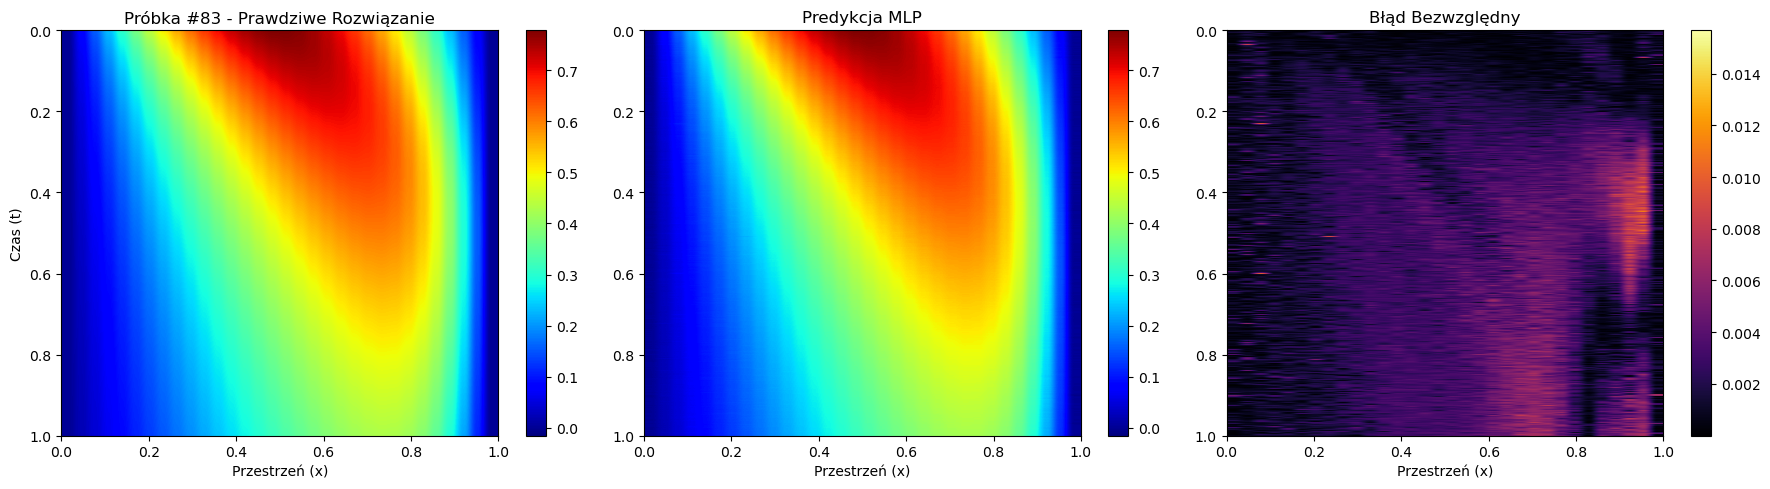

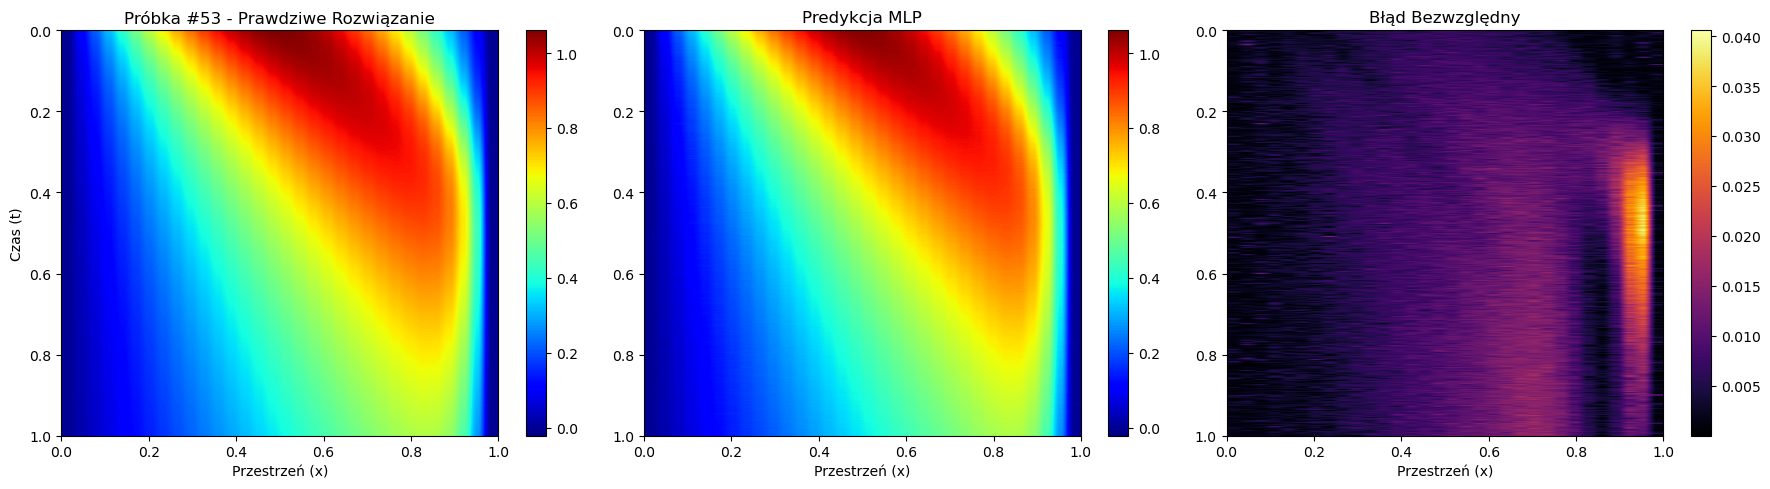

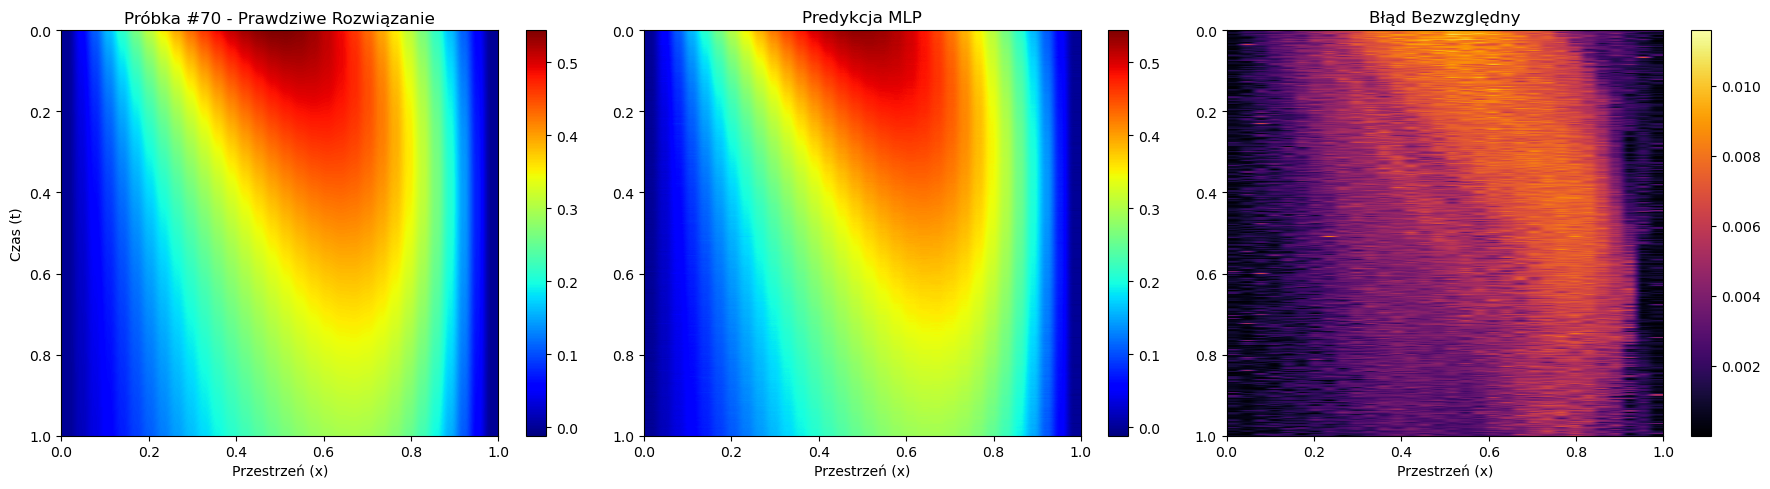

In [30]:
# Plot a few random example contours
np.random.seed(42)
random_indices = np.random.choice(len(all_preds_mesh), size=3, replace=False)
for sample_idx in random_indices:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    vmin = min(all_targets_mesh[sample_idx].min(), all_preds_mesh[sample_idx].min())
    vmax = max(all_targets_mesh[sample_idx].max(), all_preds_mesh[sample_idx].max())

    im0 = axes[0].imshow(
        all_targets_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect='auto',
        cmap='jet',
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title(f'Próbka #{sample_idx} - Prawdziwe Rozwiązanie')
    axes[0].set_ylabel('Czas (t)')
    axes[0].set_xlabel('Przestrzeń (x)')
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(
        all_preds_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect='auto',
        cmap='jet',
        vmin=vmin,
        vmax=vmax,
    )
    axes[1].set_title('Predykcja MLP')
    axes[1].set_xlabel('Przestrzeń (x)')
    fig.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(
        abs_error_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect='auto',
        cmap='inferno',
    )
    axes[2].set_title('Błąd Bezwzględny')
    axes[2].set_xlabel('Przestrzeń (x)')
    fig.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'sample_{sample_idx}_mlp_burgers_analysis.png'), dpi=300, bbox_inches='tight')
    plt.show()

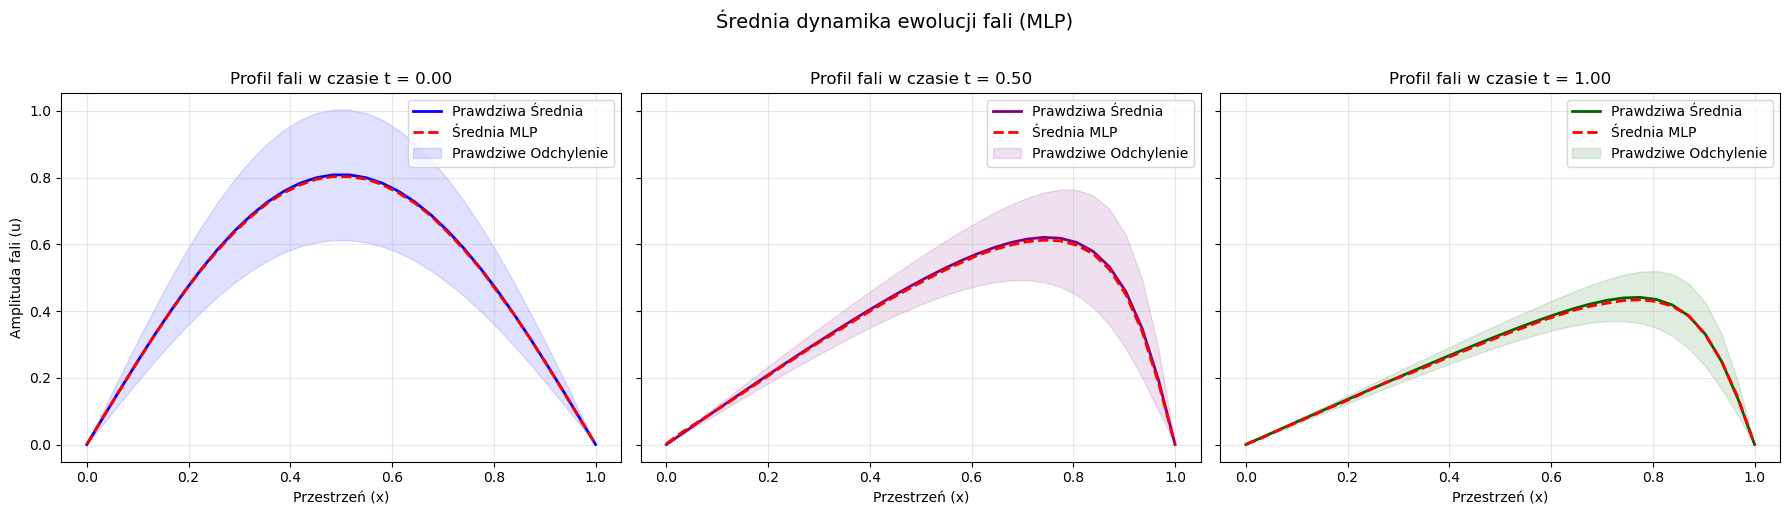

In [31]:
# Mean and standard deviation profiles at selected time slices
mean_target = all_targets_mesh.mean(axis=0)
mean_pred = all_preds_mesh.mean(axis=0)
std_target = all_targets_mesh.std(axis=0)

time_slices = [0, len(time_axis) // 2, -1]
slice_colors = ['blue', 'purple', 'darkgreen']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, t_idx in enumerate(time_slices):
    actual_t = time_axis[t_idx]
    axes[idx].plot(
        x_axis,
        mean_target[t_idx],
        color=slice_colors[idx],
        linewidth=2,
        label='Prawdziwa Średnia',
    )
    axes[idx].plot(
        x_axis,
        mean_pred[t_idx],
        color='red',
        linestyle='--',
        linewidth=2,
        label='Średnia MLP',
    )
    axes[idx].fill_between(
        x_axis,
        mean_target[t_idx] - std_target[t_idx],
        mean_target[t_idx] + std_target[t_idx],
        color=slice_colors[idx],
        alpha=0.12,
        label='Prawdziwe Odchylenie',
    )
    axes[idx].set_title(f'Profil fali w czasie t = {actual_t:.2f}')
    axes[idx].set_xlabel('Przestrzeń (x)')
    if idx == 0:
        axes[idx].set_ylabel('Amplituda fali (u)')
    axes[idx].legend(loc='upper right')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Średnia dynamika ewolucji fali (MLP)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'MLP_Burgers_averages.png'), dpi=300, bbox_inches='tight')
plt.show()